# Rede de filas de incidentes de TI

Fonte do dataset: https://archive.ics.uci.edu/dataset/498/incident+management+process+enriched+event+log

Esse python notebook contém o tratamento inicial dos dados e execução do modelo base e do modelo melhorado.
Rode os blocos em ordem.

In [1]:
import json
import os
import re
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV = "dataset/incident+management+process+enriched+event+log/incident_event_log.csv"
PERIODO = ("2016-03-01", "2016-06-01")  # meses com operação no log: base para feriados e expediente
JANELA = ("2016-04-01", "2016-06-01")  # período usado no modelo
FILAS = {"Group 70": "N1", "Group 20": "N2a", "Group 39": "N2b"}  # demais grupos = OUTROS
NOMES_FILAS = ["N1", "N2a", "N2b", "OUTROS"]
os.makedirs("resultados", exist_ok=True)
os.makedirs("modelos", exist_ok=True)


def dentro(datas, periodo):
    # True para as datas dentro do período [início, fim)
    return (datas >= periodo[0]) & (datas < periodo[1])


log = pd.read_csv(CSV, na_values="?", low_memory=False)
for coluna in ["opened_at", "sys_updated_at"]:
    log[coluna] = pd.to_datetime(log[coluna], format="%d/%m/%Y %H:%M")
log = log.sort_values(["number", "sys_updated_at", "sys_mod_count"])

## 1. Feriados
- Dias úteis com menos de 30% das aberturas de chamados de um dia útil típico são tratados como feriado. Todos os casos aqui coincidem com feriados de fato, e feriadões (dias ponte).
- Incidentes únicos aparecem em várias linhas (atualizações), para contar incidentes contamos incidentes únicos via o number

In [2]:
incidentes = log.drop_duplicates("number")
abertos = incidentes[dentro(incidentes["opened_at"], PERIODO)]

por_dia = abertos["opened_at"].dt.date.value_counts().sort_index()
dias = pd.DataFrame({"aberturas": por_dia})
dias.index = pd.to_datetime(dias.index)
dias["dia_da_semana"] = dias.index.day_name()

dias_uteis = dias[dias.index.dayofweek < 5].copy()
mediana = dias_uteis["aberturas"].median()
dias_uteis["%_da_mediana"] = (100 * dias_uteis["aberturas"] / mediana).round(1)
dias_uteis["feriado"] = dias_uteis["%_da_mediana"] < 30

# sexta santa, tiradentes, ponte de tiradentes, corpus christi, ponte de corpus christi
FERIADOS = [d.strftime("%Y-%m-%d") for d in dias_uteis[dias_uteis["feriado"]].index]

print(dias_uteis.to_string())

            aberturas dia_da_semana  %_da_mediana  feriado
opened_at                                                 
2016-03-01        315       Tuesday          86.4    False
2016-03-02        465     Wednesday         127.6    False
2016-03-03        392      Thursday         107.5    False
2016-03-04        388        Friday         106.4    False
2016-03-07        607        Monday         166.5    False
2016-03-08        434       Tuesday         119.1    False
2016-03-09        340     Wednesday          93.3    False
2016-03-10        312      Thursday          85.6    False
2016-03-11        329        Friday          90.3    False
2016-03-14        459        Monday         125.9    False
2016-03-15        382       Tuesday         104.8    False
2016-03-16        372     Wednesday         102.1    False
2016-03-17        334      Thursday          91.6    False
2016-03-18        334        Friday          91.6    False
2016-03-21        438        Monday         120.2    Fal

## 2. Horário de expediente
- As atualizações dos chamados mostram quando os atendentes trabalham. Os dados mostram que o range de horário com mais pico é entre 8h e 18h
- Registros para o estado "Closed" ficam de fora, pois parecem ser feitas por uma rotina automática de fechamento de chamado (ocorrem após status "Resolved" 5 dias depois da atualização de status, não devem ser usado então para contabilizar expediente).

In [3]:
atualizacoes = log[dentro(log["sys_updated_at"], PERIODO)]
atualizacoes = atualizacoes[atualizacoes["incident_state"] != "Closed"]

dia = atualizacoes["sys_updated_at"].dt.normalize()
eh_dia_util = (atualizacoes["sys_updated_at"].dt.dayofweek < 5) & ~dia.isin(pd.to_datetime(FERIADOS))
uteis = atualizacoes[eh_dia_util]
hora = uteis["sys_updated_at"].dt.hour
qtd_dias = uteis["sys_updated_at"].dt.normalize().nunique()

horario = pd.DataFrame({
    "atualizacoes_por_dia_util": (hora.value_counts().sort_index() / qtd_dias).round(1),
    "%_das_atualizacoes": (100 * hora.value_counts(normalize=True).sort_index()).round(1),
    "pessoas_distintas_por_dia_util": (uteis.groupby([uteis["sys_updated_at"].dt.normalize(), hora])
                                       ["sys_updated_by"].nunique().groupby(level=1).mean().round(1)),
})
horario.index.name = "hora"
print(horario.to_string())

      atualizacoes_por_dia_util  %_das_atualizacoes  pessoas_distintas_por_dia_util
hora                                                                               
0                          11.1                 0.6                             3.8
1                          13.8                 0.8                             3.8
2                           9.6                 0.6                             3.2
3                           6.2                 0.4                             3.0
4                           5.8                 0.3                             3.0
5                           4.6                 0.3                             2.6
6                           7.9                 0.5                             2.9
7                          21.3                 1.2                             6.0
8                         143.4                 8.3                            28.4
9                         191.3                11.0                         

## 3. Visitas às filas
- "Visita" é a permanência de um incidente em uma fila, da chegada do incidente a uma fila até ele sair para outra fila ou ser resolvido.
- Expediente só conta dias úteis em horário comercial
- Quando não tem grupo de atendimento, assume-se o último (ou o próximo se estava sem grupo na entrada)
- Destino é a próxima visita do incidente (uma reabertura conta como retorno). Sem destino é uma saída.

In [4]:
def minutos_uteis(t):
    dia = t.dt.normalize().values.astype("datetime64[D]")
    dias = np.busday_count("2016-01-01", dia, holidays=FERIADOS)
    minuto = np.clip(t.dt.hour * 60 + t.dt.minute, 480, 1080) - 480
    return dias * 600 + np.where(np.is_busday(dia, holidays=FERIADOS), minuto, 0)


df = log[log.incident_state != "-100"].copy()

grupo = df.groupby("number").assignment_group.ffill()
grupo = grupo.groupby(df.number).bfill()
df["fila"] = grupo.map(FILAS).fillna("OUTROS")

terminal = df.incident_state.isin(["Resolved", "Closed"])
primeira_linha = df.groupby("number").cumcount() == 0
df.loc[terminal & ~primeira_linha, "fila"] = "FIM"
df["fim"] = df.groupby("number").sys_updated_at.shift(-1)  # a linha vale até a próxima do incidente
df.loc[terminal & primeira_linha, "fim"] = df.sys_updated_at  # resolvido já no primeiro registro

nova = df.fila != df.groupby("number").fila.shift()
df["visita"] = nova.cumsum()
v = df.groupby("visita").agg(
    number=("number", "first"),
    fila=("fila", "first"),
    opened_at=("opened_at", "first"),
    t0=("sys_updated_at", "first"),
    t1=("fim", "last"),
)
v["primeira"] = ~v.number.duplicated()
v.loc[v.primeira, "t0"] = v.loc[v.primeira, ["t0", "opened_at"]].min(axis=1)  # chegada = abertura
v = v[v.fila != "FIM"].drop(columns="opened_at")

v["destino"] = v.groupby("number").fila.shift(-1).fillna("SAIDA")
v["u0"], v["u1"] = minutos_uteis(v.t0), minutos_uteis(v.t1)
v["dur"] = v.u1 - v.u0  # permanência na fila, em minutos úteis

v.to_csv("resultados/visitas.csv", index=False)
print(v.fila.value_counts().to_string())

fila
N1        17119
OUTROS    16159
N2a        3133
N2b        1735


### 3.1 Escolha das filas
O log tem 78 grupos de atendimento. Uma fila por grupo deixaria o modelo grande demais e com parâmetros pouco confiáveis nos grupos pequenos. Por isso a rede usa os três grupos que têm um papel claro no fluxo e junta os demais em uma fila só:

- **N1 = Group 70**: a porta de entrada. Recebe 52% das aberturas, tem 40% de todas as visitas e é o último grupo de 45% dos incidentes. É o primeiro nível de atendimento.
- **N2a = Group 20** e **N2b = Group 39**: os dois destinos principais quando o N1 escala um chamado, com cerca de 17% dos escalonamentos do Group 70 cada. O próximo destino, o Group 25, recebe só 7%. Funcionam como segundo nível.
- **OUTROS**: os outros 75 grupos, nenhum com mais de 4,3% das visitas. Juntos são cerca de metade das visitas, então não dá para descartá-los, mas nenhum tem volume para virar uma fila própria. O Group 25 tem mais visitas que o Group 39, mas a maioria vem de aberturas diretas e não de escalonamentos do N1, por isso ficou em OUTROS.

Como OUTROS junta grupos muito diferentes, os seus servidores e o seu tempo de atendimento são uma média desses grupos e não descrevem uma equipe real. Esse é um limite do modelo.

A tabela abaixo usa o log inteiro e mostra os números que justificam a escolha.

In [5]:
# cada troca de grupo dentro de um incidente conta como uma visita ao novo grupo
g = df.assign(grupo=grupo)
g = g[g.grupo != g.groupby("number").grupo.shift()].copy()
g["anterior"] = g.groupby("number").grupo.shift()

grupos = pd.DataFrame({
    "%_das_visitas": g.grupo.value_counts(normalize=True),
    "%_das_aberturas": g[g.anterior.isna()].grupo.value_counts(normalize=True),
    "%_dos_escalonamentos_do_N1": g[g.anterior == "Group 70"].grupo.value_counts(normalize=True),
    "%_ultimo_grupo_do_incidente": g.groupby("number").grupo.last().value_counts(normalize=True),
}).fillna(0).mul(100).round(1).sort_values("%_das_visitas", ascending=False)
grupos.insert(0, "fila", grupos.index.map(FILAS).fillna("OUTROS"))

print(f"{len(grupos)} grupos de atendimento; os 8 com mais visitas:")
print(grupos.head(8).to_string())

78 grupos de atendimento; os 8 com mais visitas:
            fila  %_das_visitas  %_das_aberturas  %_dos_escalonamentos_do_N1  %_ultimo_grupo_do_incidente
grupo                                                                                                    
Group 70      N1           39.7             52.5                         0.0                         45.0
Group 20     N2a            7.2              5.7                        16.8                          1.8
Group 25  OUTROS            4.3              3.2                         7.3                          5.2
Group 39     N2b            3.9              1.6                        16.9                          4.9
Group 24  OUTROS            3.5              2.9                         4.5                          4.3
Group 23  OUTROS            2.3              1.2                         3.8                          3.3
Group 73  OUTROS            2.1              2.0                         2.0                          2

## 4. Parâmetros das filas
Chegadas, atendimento, servidores e roteamento de cada fila em abril e maio de 2016.

- Servidores se considerou como número máximo de incidentes que a fila manteve aberto ao mesmo tempo na janela de tempo.

In [6]:
janela = v[dentro(v.t0, JANELA)]  # visitas iniciadas na janela
inicio_util, fim_util = minutos_uteis(pd.Series(pd.to_datetime(JANELA)))
T = fim_util - inicio_util  # minutos úteis da janela
amostras = np.arange(inicio_util, fim_util, 10)  # a cada 10 minutos úteis

par = {}
for f in NOMES_FILAS:
    s = janela[janela.fila == f]
    chegada = T / s.primeira.sum()  # intervalo médio entre chegadas externas (min)
    atendimento = s.dur.mean()  # tempo médio de atendimento = permanência (min)
    todas = v[v.fila == f]
    abertos = np.searchsorted(np.sort(todas.u0), amostras, "right") - np.searchsorted(np.sort(todas.u1), amostras,
                                                                                      "right")
    servidores = int(abertos.max())
    rot = s.destino.value_counts(normalize=True)
    par[f] = {
        "chegada": [0, round(float(2 * chegada), 2)],  # uniforme com a média observada
        "atendimento": [0, round(float(2 * atendimento), 2)],  # uniforme com a média observada
        "servidores": servidores,
        "mu_por_hora": round(float(60 / atendimento), 4),
        "rho": round(float(len(s) / T * atendimento / servidores), 3),  # lambda * S / C (precisa ser < 1)
        "roteamento": {d: round(float(rot.get(d, 0)), 4) for d in NOMES_FILAS},  # o resto vai para a saída
    }
    print(f, par[f])

json.dump(par, open("resultados/parametros.json", "w"), indent=2)

N1 {'chegada': [0, 5.67], 'atendimento': [0, 493.25], 'servidores': 358, 'mu_por_hora': 0.2433, 'rho': 0.318, 'roteamento': {'N1': 0.0067, 'N2a': 0.0485, 'N2b': 0.0653, 'OUTROS': 0.1936}}
N2a {'chegada': [0, 48.2], 'atendimento': [0, 2721.23], 'servidores': 151, 'mu_por_hora': 0.0441, 'rho': 0.741, 'roteamento': {'N1': 0.3371, 'N2a': 0.0, 'N2b': 0.001, 'OUTROS': 0.4852}}
N2b {'chegada': [0, 199.15], 'atendimento': [0, 1220.13], 'servidores': 88, 'mu_por_hora': 0.0984, 'rho': 0.338, 'roteamento': {'N1': 0.2743, 'N2a': 0.0009, 'N2b': 0.0184, 'OUTROS': 0.0386}}
OUTROS {'chegada': [0, 7.83], 'atendimento': [0, 6179.97], 'servidores': 1212, 'mu_por_hora': 0.0194, 'rho': 0.996, 'roteamento': {'N1': 0.1649, 'N2a': 0.0456, 'N2b': 0.0176, 'OUTROS': 0.008}}


## 5. Modelo do simulador
Escreve `modelos/base.yml` com os parâmetros acima.

In [7]:
linhas = ["# Rede de incidentes de TI (abr-mai/2016). Tempo em minutos úteis (8h-18h, dias úteis).",
          "# Gerado pelo notebook a partir de resultados/parametros.json",
          "simulation:", "  max_randoms: 1000000", "  seed: 42", "", "queues:"]
for fila, p in par.items():
    linhas += [f"  {fila}:                 # G/G/{p['servidores']} (capacidade infinita)",
               f"    servers: {p['servidores']}",
               f"    arrival: [{p['chegada'][0]}, {p['chegada'][1]}]",
               f"    service: [{p['atendimento'][0]}, {p['atendimento'][1]}]",
               "    routing:"]
    linhas += [f"      {d}: {prob}" for d, prob in p["roteamento"].items() if prob > 0]
    linhas += ["      # o restante vai para o exterior (incidente resolvido)", ""]

open("modelos/base.yml", "w").write("\n".join(linhas))

1267

## 6. Simulação e índices do M9
Roda o simulador (cerca de 1 minuto) e calcula N, D, U e W de cada fila. Para o modelo melhorado: `indices("modelos/melhorado.yml")`.

In [8]:
def indices(yml):
    nome = yml.split("/")[-1].removesuffix(".yml")
    saida = subprocess.run([sys.executable, "simulator.py", yml], capture_output=True, text=True, check=True).stdout
    open(f"resultados/{nome}_saida.txt", "w").write(saida)

    linhas = []
    # cada fila: cabeçalho "== N1 (G/G/C/infinite) ==", linha "Service interval: [a, b]", perdas e tabela de estados
    for fila, C, corpo in re.findall(r"=+ (\S+) \(G/G/(\d+)/\w+\) =+\n(.*?)(?=\n=+ |\nTotal clients lost \(all)", saida,
                                     re.S):
        C = int(C)
        a, b = map(float, re.search(r"Service interval: \[([\d.]+), ([\d.]+)\]", corpo).groups())
        mu = 1 / ((a + b) / 2)  # taxa de atendimento por servidor (por minuto útil)
        perdas = int(re.search(r"Total clients lost: (\d+)", corpo).group(1))
        estados = [(int(i), float(p)) for i, p in re.findall(r"^\s+(\d+)\*?\s+[\d.]+\s+([\d.]+)", corpo, re.M)]
        N = sum(p * i for i, p in estados)  # população
        D = sum(p * min(i, C) * mu for i, p in estados)  # vazão (por minuto útil)
        U = sum(p * min(i, C) / C for i, p in estados)  # utilização
        linhas.append({"fila": fila, "servidores": C, "K (maior estado)": max(i for i, _ in estados),
                       "perdas": perdas, "N": N, "D (por hora)": 60 * D, "U": U, "W (min)": N / D,
                       "P(todos ocupados)": sum(p for i, p in estados if i >= C)})

    tabela = pd.DataFrame(linhas).set_index("fila")
    tabela.to_csv(f"resultados/{nome}_indices.csv")
    return tabela.round(3)


indices("modelos/base.yml")

,servidores,K (maior estado),perdas,N,D (por hora),U,W (min),P(todos ocupados)
fila,,,,,,,,
N1,358,146,0,113.049,27.503,0.316,246.625,0.00
N2a,151,137,0,109.358,4.822,0.724,1360.615,0.00
N2b,88,51,0,29.058,2.858,0.330,610.065,0.00
OUTROS,1212,1438,0,1225.595,23.161,0.984,3174.953,0.55


### 6.1 Distribuição de probabilidades
Para cada fila, o simulador informa a probabilidade P(i) de a fila ter i chamados (em atendimento ou esperando). Os gráficos mostram essas distribuições. A linha tracejada marca o número de servidores C: à esquerda dela todos os chamados estão em atendimento, e à direita há chamados esperando. A tabela resume cada distribuição. `distribuicao("base", "melhorado")` sobrepõe os dois modelos.

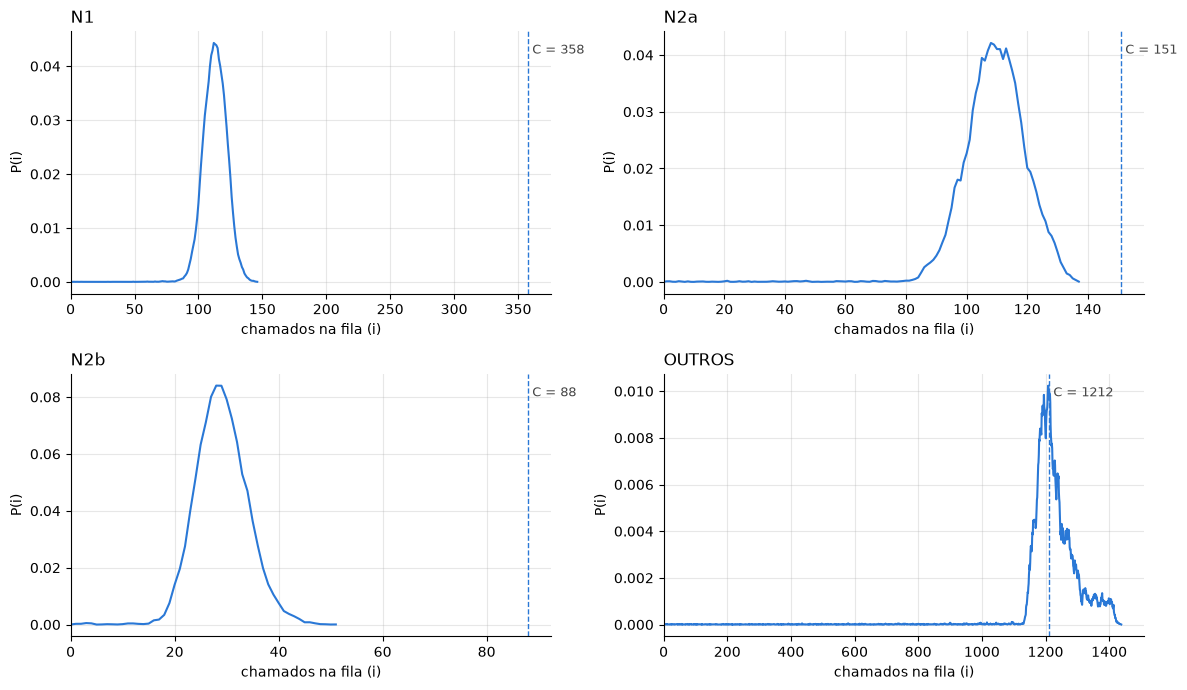

,,servidores,P(0),moda,N (média),faixa de 90%,maior estado,P(i >= C),P(i > C)
fila,modelo,,,,,,,,
N1,base,358,0.0,112,113.049,99 a 127,146,0.00,0.00
N2a,base,151,0.0,108,109.358,94 a 125,137,0.00,0.00
N2b,base,88,0.0,28,29.058,21 a 37,51,0.00,0.00
OUTROS,base,1212,0.0,1209,1225.595,1156 a 1366,1438,0.55,0.54


In [9]:
CORES = ["#2a78d6", "#eb6834"]  # uma cor por modelo, na ordem em que são passados


def distribuicao(*nomes):
    # lê a tabela de estados que indices() salvou em resultados/<nome>_saida.txt
    dist = {}
    for nome in nomes:
        saida = open(f"resultados/{nome}_saida.txt").read()
        for fila, C, corpo in re.findall(r"=+ (\S+) \(G/G/(\d+)/\w+\) =+\n(.*?)(?=\n=+ |\nTotal clients lost \(all)",
                                         saida, re.S):
            estados = re.findall(r"^\s+(\d+)\*?\s+[\d.]+\s+([\d.]+)", corpo, re.M)
            dist[nome, fila] = int(C), pd.Series({int(i): float(p) for i, p in estados})

    resumo = []
    fig, eixos = plt.subplots(2, 2, figsize=(12, 7))
    for eixo, fila in zip(eixos.flat, NOMES_FILAS):
        for k, (nome, cor) in enumerate(zip(nomes, CORES)):
            C, p = dist[nome, fila]
            acum = p.cumsum()
            quantil = lambda q: p.index[min(acum.searchsorted(q), len(p) - 1)]
            resumo.append({"fila": fila, "modelo": nome, "servidores": C, "P(0)": p.get(0, 0.0),
                           "moda": p.idxmax(), "N (média)": (p.index * p).sum(),
                           "faixa de 90%": f"{quantil(0.05)} a {quantil(0.95)}", "maior estado": p.index.max(),
                           "P(i >= C)": p[p.index >= C].sum(), "P(i > C)": p[p.index > C].sum()})
            eixo.plot(p.index, p.values, color=cor, lw=1.5, label=nome)
            eixo.axvline(C, color=cor, ls="--", lw=1)
            eixo.text(C, 0.95 - 0.08 * k, f" C = {C}", transform=eixo.get_xaxis_transform(), color="#444",
                      fontsize=9, va="top")
        eixo.set_title(fila, loc="left")
        eixo.set_xlabel("chamados na fila (i)")
        eixo.set_ylabel("P(i)")
        eixo.set_xlim(left=0)
        eixo.grid(alpha=0.3)
        eixo.spines[["top", "right"]].set_visible(False)
        if len(nomes) > 1:
            eixo.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(resumo).set_index(["fila", "modelo"]).round(3)


distribuicao("base")

**Leitura das distribuições do modelo base**
- **N1, N2a e N2b** têm distribuições estreitas e ficam bem à esquerda de C, então nenhuma delas forma fila. O N1 nunca passou de 146 chamados com 358 servidores, e o N2b nunca passou de 51 com 88. O N2a é o que chega mais perto (no máximo 137 de 151 servidores), mas P(i ≥ C) continua 0: nenhum chamado espera.
- **OUTROS** é a única fila que passa de C. A distribuição fica em cima da linha (mediana de cerca de 1217 com C = 1212) e vai até 1438. Em 55% do tempo todos os servidores estão ocupados, e nesses momentos chega a haver até 226 chamados esperando. É o gargalo da rede.
- P(0) = 0 em todas as filas, ou seja, nenhuma fica vazia. O atendimento leva de horas a dias, muito mais que o intervalo entre chegadas, então sempre há chamados abertos.

### 6.2 Perdas
Todas as filas têm capacidade infinita (o campo `capacity` não aparece no yml), então nenhum chamado é perdido. A coluna `perdas` da tabela de índices é 0 em todas as filas, e o total do simulador também é 0 (abaixo).

Isso é intencional e corresponde ao sistema real: um service desk não recusa incidentes. Quando a equipe está sobrecarregada, o chamado fica no backlog esperando atendimento. Por isso, ao contrário do exemplo do M9, em que a lotação aparecia como pacientes perdidos, aqui a saturação aparece como **espera**: estados acima de C na distribuição, P(todos ocupados) e aumento de W. São esses indicadores, e não as perdas, que usamos para comparar o modelo base com o melhorado.

In [10]:
re.search(r"Total clients lost \(all queues\): \d+", open("resultados/base_saida.txt").read()).group()

'Total clients lost (all queues): 0'

## 7. Melhoria Sugerida

**Gargalos identificados no modelo base**
- **OUTROS** é o gargalo principal: utilização de 0,984, todos os servidores ocupados em 55% do tempo, e é a única fila com espera (cerca de 85 minutos úteis). Recebe 19,4% do que sai do N1 e 48,5% do que sai do N2a.
- **N2a** é o ponto de atenção seguinte (utilização de 0,724). N1 e N2b estão folgados (utilização de cerca de 0,32), com capacidade de sobra.

**Alterações em `modelos/melhorado.yml`**
1. **Triagem melhor no N1:** `N1.routing.OUTROS` de 0,1936 para 0,10. Com base de conhecimento e scripts de resolução, parte dos chamados que hoje sobem para OUTROS passa a ser resolvida no próprio N1; essa diferença vai para a saída. O N1 tem folga para absorver isso.
2. **Mais capacidade no gargalo:** `OUTROS.servers` de 1212 para 1300 (+88 vagas de atendimento simultâneo, cerca de 7%).

**Efeito esperado** (equações de tráfego, antes de simular): a chegada total em OUTROS cai de 23,35 para 20,61 por hora, e o `rho` de OUTROS cai de 0,992 para 0,817. Cada alteração sozinha levaria o `rho` a cerca de 0,93; juntas, atacam a causa (menos carga) e o gargalo (mais capacidade). N1, N2a e N2b também ficam um pouco menos carregadas (N2a: de 0,736 para 0,713), porque menos chamados retornam de OUTROS.

Rode o código abaixo para simular o modelo melhorado e comparar com a tabela da seção 6.

In [11]:
indices("modelos/melhorado.yml")

,servidores,K (maior estado),perdas,N,D (por hora),U,W (min),P(todos ocupados)
fila,,,,,,,,
N1,358,150,0,110.851,26.968,0.310,246.625,0
N2a,151,139,0,106.598,4.701,0.706,1360.615,0
N2b,88,50,0,28.570,2.810,0.325,610.065,0
OUTROS,1300,1157,0,1054.066,20.467,0.811,3089.985,0
